In [2]:
import random
import numpy as np
import matplotlib.pyplot as plt
from autograd.scalar.engine import Value
from autograd.scalar.graphic import draw_dot
from autograd.scalar.nn import MLP, cross_entropy_loss
%matplotlib inline
%load_ext autoreload
%autoreload 2

In [ ]:
# Dummy Forward pass thorugh a single neuron with tanh activation and MSE loss

x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
b = Value(6.8813, label='b')

x1w1 = x1 * w1; x1w1.label = 'x1*w1'
x2w2 = x2 * w2; x2w2.label = 'x2*w2'
n = x1w1 + x2w2; n.label = 'x1w1 + x2w2'

n = n + b; n.label = 'x1w1 + x2w2 + b'


act = n.tanh(); act.label = 'act'
target = Value(0.7, label='target')
diff = act - target; diff.label = 'act - target'
loss = diff ** 2; loss.label = 'loss'

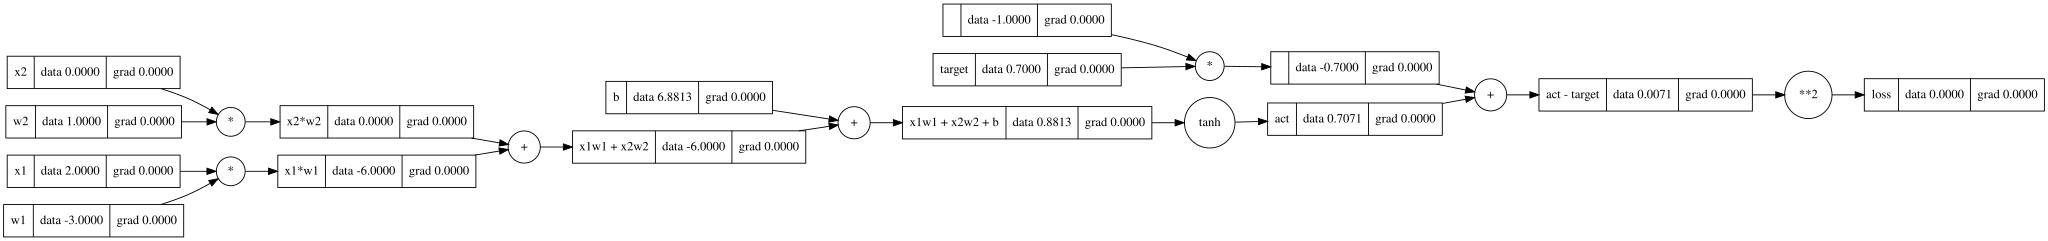

In [10]:
# Visualize the computation graph if the forward pass
draw_dot(loss)

In [ ]:
# Backward pass — compute gradients for all node
loss.backward()

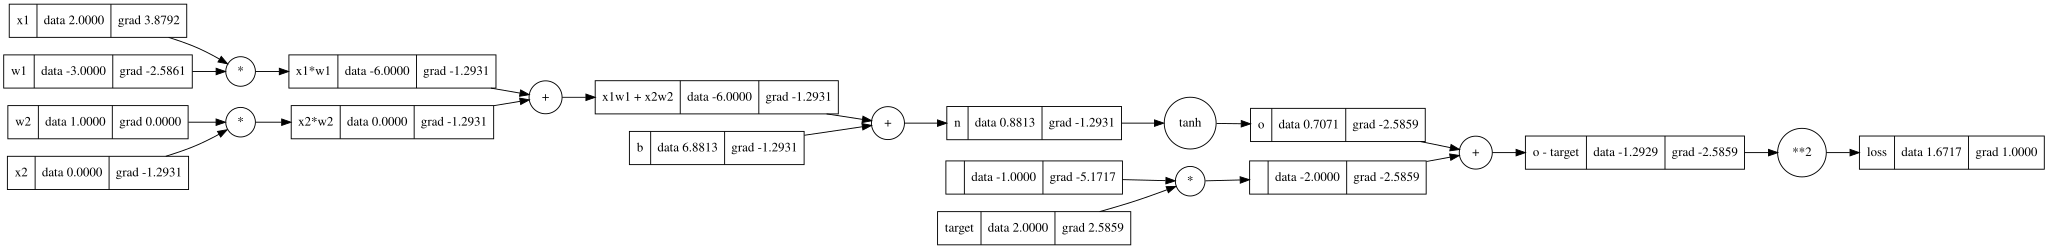

In [ ]:
# Visualize the computation graph with updated gradients
draw_dot(loss)

### Building a neural net for classification

In [24]:
# Setting random seed for reproducibility
np.random.seed(1337)
random.seed(1337)

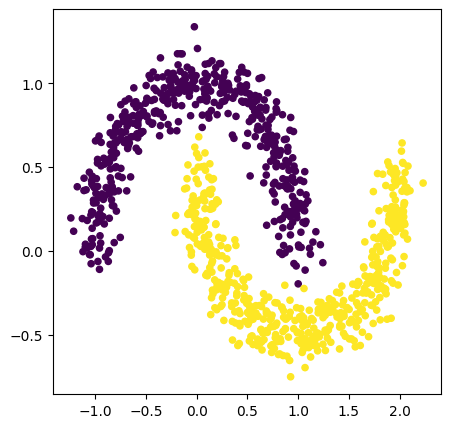

In [25]:
# Creating the dataset
from sklearn.datasets import make_moons
X, y = make_moons(n_samples=1000, noise=0.1)

# visualize in 2D
plt.figure(figsize=(5,5))
plt.scatter(X[:,0], X[:,1], c=y, s=20, cmap='viridis')

In [26]:
# Initializing a model 
model = MLP(2, [32, 16, 2])
print(model)
print("Number of parameters", len(model.parameters()))

MLP(
  (0): ReLULayer(in=2, out=32)
  (1): ReLULayer(in=32, out=16)
  (2): LinearLayer(in=16, out=2)
)
Number of parameters 658


In [27]:
# Training the model
batch_size = 128
max_steps = 100
learning_rate = 1

train_losses = []
train_accs = []

for step in range(max_steps):
    ri = np.random.choice(X.shape[0], batch_size, replace=False)
    Xb, yb = X[ri], y[ri]

    # Convert inputs to Value objects
    inputs = [list(map(Value, xrow)) for xrow in Xb]

    # Forward pass
    y_pred = list(map(model, inputs))

    # Compute loss (mean cross-entropy + L2 regularization)
    losses = [cross_entropy_loss(logits, int(label)) for logits, label in zip(y_pred, yb)]
    data_loss = sum(losses[1:], losses[0]) * (1.0 / len(losses))
    l2_reg = sum((p * p for p in model.parameters()), Value(0.0))
    total_loss = data_loss + 1e-4 * l2_reg

    acc = sum(
        (logits[1].data > logits[0].data) == bool(label)
        for logits, label in zip(y_pred, yb)
    ) / len(yb)

    model.zero_grad()
    total_loss.backward()

    # SGD with linear lr decay
    lr = learning_rate - 0.9 * learning_rate * step / max_steps
    for p in model.parameters():
        p.data -= lr * p.grad

    train_losses.append(total_loss.data)
    train_accs.append(acc)

    if step % 10 == 0:
        print(f"Step {step:3d} | Loss: {total_loss.data:.4f} | Accuracy: {acc*100:.2f}%")


Step   0 | Loss: 0.5819 | Accuracy: 72.66%
Step  10 | Loss: 0.2884 | Accuracy: 85.94%
Step  20 | Loss: 0.2051 | Accuracy: 94.53%
Step  30 | Loss: 0.1818 | Accuracy: 92.97%
Step  40 | Loss: 0.1068 | Accuracy: 98.44%
Step  50 | Loss: 0.1363 | Accuracy: 98.44%
Step  60 | Loss: 0.1036 | Accuracy: 97.66%
Step  70 | Loss: 0.0850 | Accuracy: 99.22%
Step  80 | Loss: 0.0700 | Accuracy: 99.22%
Step  90 | Loss: 0.0680 | Accuracy: 99.22%


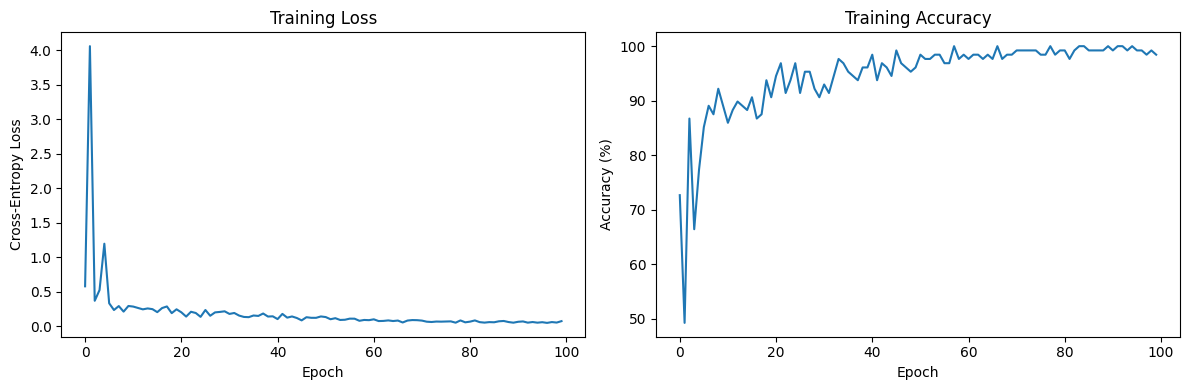

In [28]:
# Plot training loss and accuracy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(train_losses)
ax1.set_title("Training Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Cross-Entropy Loss")

ax2.plot([a * 100 for a in train_accs])
ax2.set_title("Training Accuracy")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")

plt.tight_layout()
plt.savefig("../images/scaler_loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()


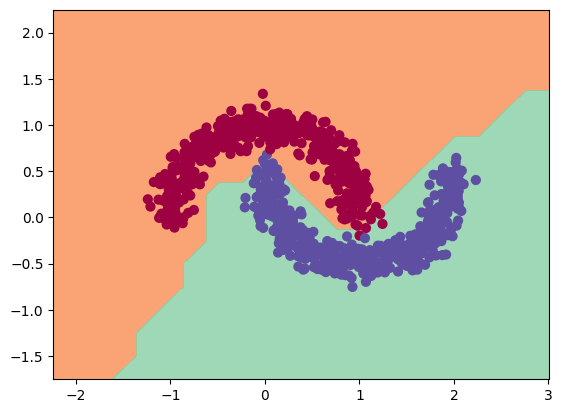

In [29]:
# Visualize decision boundary

h = 0.25
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))
Xmesh = np.c_[xx.ravel(), yy.ravel()]
inputs = [list(map(Value, xrow)) for xrow in Xmesh]
scores = list(map(model, inputs))
Z = np.array([s[1].data > s[0].data for s in scores])
Z = Z.reshape(xx.shape)

fig = plt.figure()
plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral, alpha=0.8)
plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral)
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.savefig("../images/scaler_decision_boundary.png", dpi=150, bbox_inches="tight")
plt.show()
